# Práctica 8: Pronóstico (Forecasting)

Se creo un modelo de regresión lineal con los streams de semanas anteriores (semanas existentes) para predecir los streams totales de las siguientes semanas, se evalúa con las últimas semanas del dataset y después se pronostican 4 semanas a futuro.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

PATH_INPUT = "../data/processed/spotify_cleaned.csv"
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## Carga de datos

Como en el dataset hay canciones con mas de un artista y hay una fila por cada artista de la canción, entonces se deja una sola fila por canción (sin importar el artista), semana y país para no contar los streams dos veces. Después se suman los streams de cada semana para tener la serie de tiempo (en millones).

In [2]:
df = pd.read_csv(PATH_INPUT)
df["week"] = pd.to_datetime(df["week"], format="%d-%m-%Y")

df = df.drop_duplicates(["uri", "week", "country"])
serie = df.groupby("week")["streams"].sum() / 1e6

print(f"Semanas: {len(serie)}  ({serie.index.min().date()} a {serie.index.max().date()})")
print(serie.describe().round(2))

Semanas: 76  (2021-02-04 a 2022-07-14)
count     76.00
mean     169.24
std       15.48
min      144.08
25%      159.47
50%      167.68
75%      175.48
max      219.03
Name: streams, dtype: float64


## Variables

Se usan como variables los streams de las 3 semanas anteriores (rezagos), así el modelo predice cada semana a partir de lo que pasó en las semanas previas.

In [3]:
rezagos = 3
datos = pd.DataFrame({"streams": serie})
for i in range(1, rezagos + 1):
    datos[f"lag_{i}"] = serie.shift(i)

# las primeras semanas no tienen semanas anteriores
datos = datos.dropna()
X = datos.drop(columns="streams")
y = datos["streams"]

## División de datos

El modelo se entrena con las semanas más viejas y se prueba con las últimas 12 semanas.

In [4]:
n_test = 12
X_train, X_test = X[:-n_test], X[-n_test:]
y_train, y_test = y[:-n_test], y[-n_test:]

## Modelo y evaluación

Para poder evaluar el modelo se compara contra un pronóstico "ingenuo" que solo repite el valor de la semana anterior, para ver si el modelo realmente aporta algo.

In [5]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

# pronostico ingenuo: la semana anterior
y_ingenuo = X_test["lag_1"]

print(f"Modelo   MAE = {mean_absolute_error(y_test, y_pred):.2f} M  MAPE = {mean_absolute_percentage_error(y_test, y_pred):.2%}")
print(f"Ingenuo  MAE = {mean_absolute_error(y_test, y_ingenuo):.2f} M  MAPE = {mean_absolute_percentage_error(y_test, y_ingenuo):.2%}")
print("\nCoeficientes:")
print(pd.Series(modelo.coef_, index=X.columns).round(3))

Modelo   MAE = 7.67 M  MAPE = 4.60%
Ingenuo  MAE = 8.40 M  MAPE = 5.01%

Coeficientes:
lag_1    0.644
lag_2   -0.004
lag_3    0.047
dtype: float64


## Pronóstico de semanas futuras

Se vuelve a entrenar el modelo con todas las semanas y se predicen 4 semanas nuevas. Como no se conocen los streams futuros, cada predicción, es decir cada semana "nueva" que va surgiendo a partir de predicciones se usa como rezago para predecir la semana siguiente. Decidí hacer un ponostico de 4 semanas en lugar de solo una para que en la linea de tiempo no salga solo 1 punto de predicción

In [6]:
modelo.fit(X, y)

semanas_futuras = 4
ultimos = list(serie[-rezagos:])
fechas = pd.date_range(serie.index[-1], periods=semanas_futuras + 1, freq="7D")[1:]
pronostico = []

for _ in range(semanas_futuras):
    # el lag_1 es la semana mas reciente
    entrada = pd.DataFrame([ultimos[::-1]], columns=X.columns)
    pred = modelo.predict(entrada)[0]
    pronostico.append(pred)
    ultimos = ultimos[1:] + [pred]

pronostico = pd.Series(pronostico, index=fechas)
print(pronostico.round(2))

2022-07-21    159.93
2022-07-28    162.73
2022-08-04    164.54
2022-08-11    165.88
Freq: 7D, dtype: float64


## Gráfica

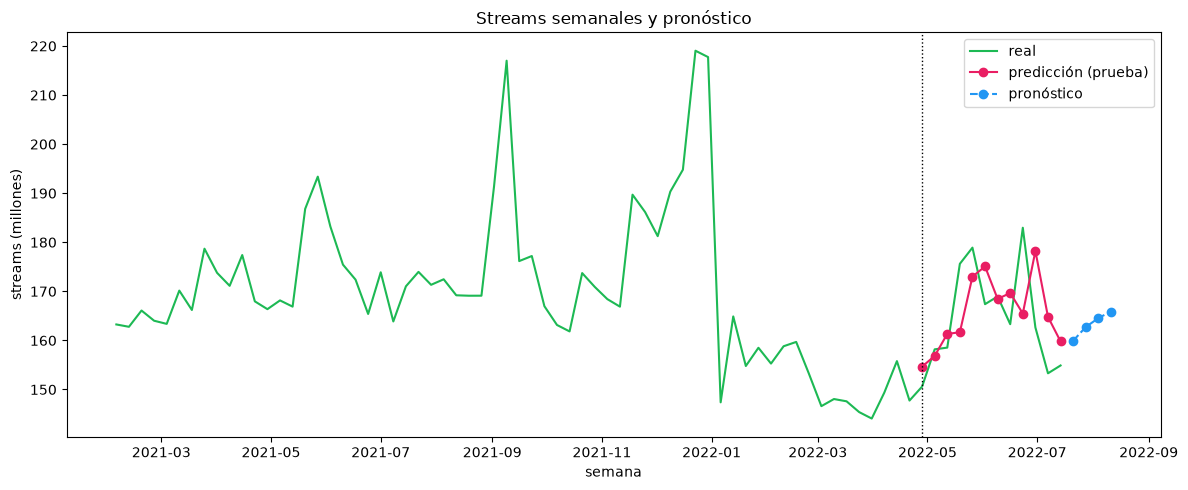

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(serie.index, serie, color="#1DB954", label="real")
ax.plot(y_test.index, y_pred, color="#E91E63", marker="o", label="predicción (prueba)")
ax.plot(pronostico.index, pronostico, color="#2196F3", marker="o", ls="--", label="pronóstico")
ax.axvline(y_test.index[0], color="black", ls=":", lw=1)

ax.set_xlabel("semana")
ax.set_ylabel("streams (millones)")
ax.set_title("Streams semanales y pronóstico")
ax.legend()

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "pronostico_streams.png"), dpi=150)
plt.show()

Con 3 semanas anteriores el modelo tiene un error medio de 7.67 millones de streams en las 12 semanas de prueba (MAPE de 4.60%), un poco mejor que el pronóstico ingenuo de repetir la semana anterior (8.40 millones, 5.01%).

En los coeficientes se ve que casi todo el peso lo tiene `lag_1` (0.644) y que `lag_2` y `lag_3` casi no aportan, es decir, la semana más reciente es la que más sirve para predecir la siguiente. Como el coeficiente es menor a 1, el modelo tiende a regresar los valores hacia el promedio de la serie.

En la gráfica se ve que las predicciones de prueba siguen la tendencia pero con una semana de retraso, porque el modelo solo reacciona a los picos después de que pasan. Los picos más grandes de la serie (mayo y septiembre de 2021 y finales de diciembre) vienen de eventos como lanzamientos de álbumes grandes o las canciones navideñas, que no se pueden anticipar solo con los streams anteriores.

Por eso el pronóstico de las 4 semanas futuras sube poco a poco de 159.9 a 165.9 millones, que es la forma en que el modelo regresa al promedio después de una semana baja. Este pronóstico sirve para dar una idea del nivel normal de streams, pero no puede predecir los picos ni las temporadas altas de streams por festividades, y además entre más lejos está la semana menos confiable es, ya que cada predicción depende de las predicciones anteriores.